# Experiment 04: Clustering Analysis using K-Means
**Aim:** Implement K-Means clustering algorithm on Iris dataset and determine optimal clusters using Elbow method.

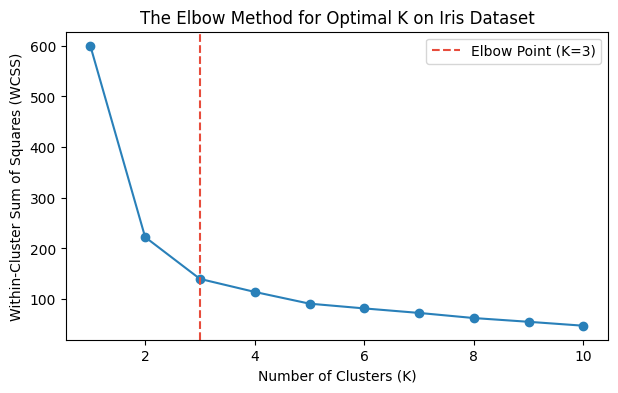

In [5]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import load_iris
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import silhouette_score

# 1. Load & Standardize Features
iris = load_iris()
X = StandardScaler().fit_transform(iris.data)

# 2. Apply Elbow Method
wcss = [KMeans(n_clusters=k, init='k-means++', random_state=42, n_init=10).fit(X).inertia_ for k in range(1, 11)]

plt.figure(figsize=(7, 4))
plt.plot(range(1, 11), wcss, marker='o', color='#2980b9')
plt.axvline(3, color='#e74c3c', linestyle='--', label='Elbow Point (K=3)')
plt.title('The Elbow Method for Optimal K on Iris Dataset')
plt.xlabel('Number of Clusters (K)')
plt.ylabel('Within-Cluster Sum of Squares (WCSS)')
plt.legend()
plt.show()

Silhouette Score (K=3): 0.4599

Actual vs Cluster Distribution:
 Cluster   0   1   2
Actual             
0         0  50   0
1        39   0  11
2        14   0  36


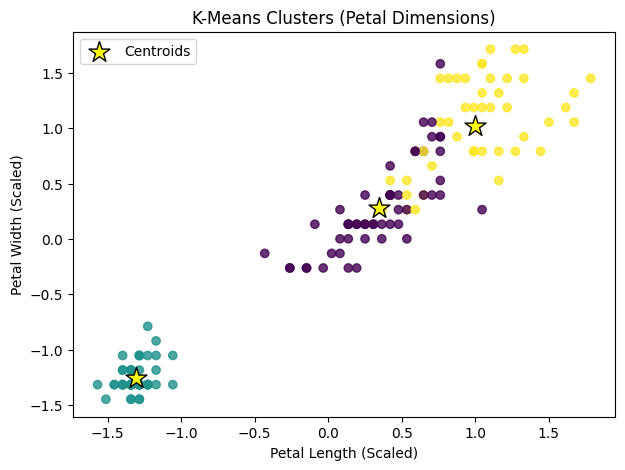

In [6]:
# 3. Train K-Means (K=3) & Evaluate
kmeans = KMeans(n_clusters=3, init='k-means++', random_state=42, n_init=10).fit(X)
print(f"Silhouette Score (K=3): {silhouette_score(X, kmeans.labels_):.4f}\n")

crosstab = pd.crosstab(iris.target, kmeans.labels_, rownames=['Actual'], colnames=['Cluster'])
print("Actual vs Cluster Distribution:\n", crosstab)

# 4. Scatter Plot of Clusters & Centroids
plt.figure(figsize=(7, 5))
plt.scatter(X[:, 2], X[:, 3], c=kmeans.labels_, cmap='viridis', alpha=0.8)
plt.scatter(kmeans.cluster_centers_[:, 2], kmeans.cluster_centers_[:, 3], s=250, c='yellow', marker='*', edgecolors='black', label='Centroids')
plt.title('K-Means Clusters (Petal Dimensions)')
plt.xlabel('Petal Length (Scaled)')
plt.ylabel('Petal Width (Scaled)')
plt.legend()
plt.show()